### Dependencies

In [284]:
import math
import random

### Visualizer

In [285]:
from graphviz import Digraph


def build(v, nodes, edges):
    if v not in nodes:
        nodes.add(v)
        for child in v._prev:
            edges.add((child, v))
            build(child, nodes, edges)


def trace(root):
    nodes, edges = set(), set()
    build(root, nodes, edges)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(
            name=uid,
            label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}",
            shape="record",
        )
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

### Micrograd

In [286]:
class Value:
    def __init__(self, data: float, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other):
        return self * other

    def __neg__(self):  # -self
        return self * -1

    def __sub__(self, other):  # self - other
        return self + (-other)

    def __rsub__(self, other):  # other - self
        return other + (-self)

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += other * self.data ** (other - 1) * out.grad

        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other**-1

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward

        return out

    def tanh(self):
        out = Value(
            (math.exp(2 * self.data) - 1) / (math.exp(2 * self.data) + 1),
            (self,),
            "tanh",
        )

        def _backward():
            self.grad += (1 - out.data**2) * out.grad

        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

### Neural Network

In [287]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

In [288]:
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

In [289]:
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

### Forward Pass

In [290]:
x = [2.0, 3.0]
n = Neuron(len(x))
n(x)

Value(data=0.9997344884921591)

In [291]:
x = [2.0, 3.0]
n = Layer(len(x), 3)
n(x)

[Value(data=0.9985787931133847),
 Value(data=-0.8368088726612422),
 Value(data=0.7794929481321227)]

In [292]:
x = [2.0, 3.0, -1.0]
n = MLP(len(x), [4, 4, 1])
y = n(x)
y

Value(data=-0.6424874300269096)

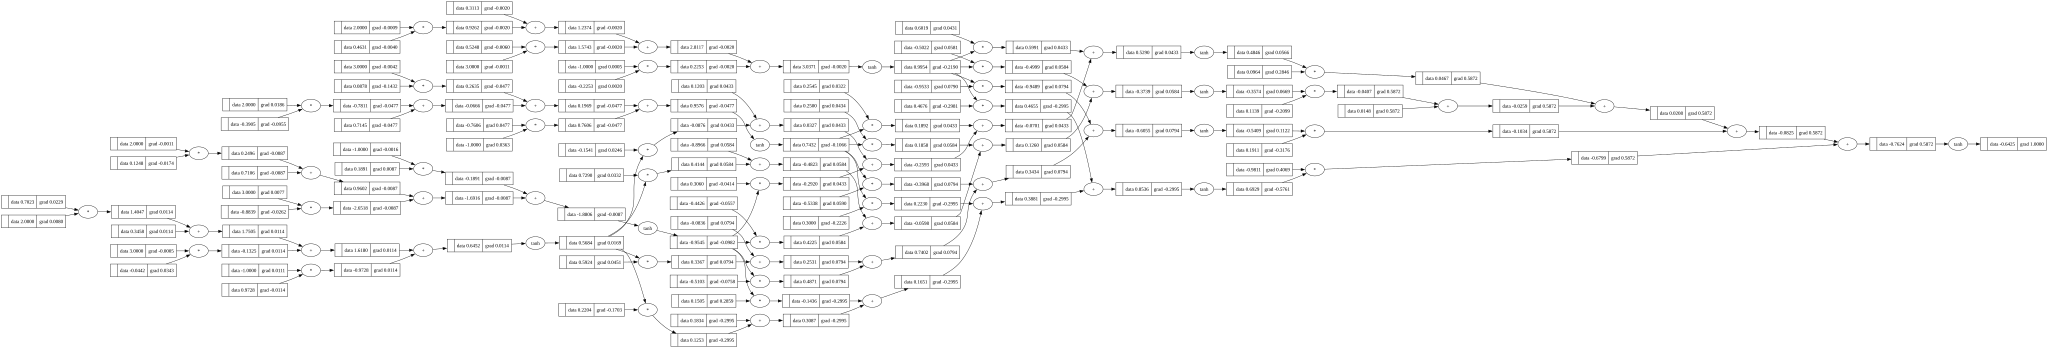

In [293]:
y.backward()
draw_dot(y)

### Tuning Parameters

In [294]:
xs = [[2.0, 3.0, -1.0], [3.0, -1.0, 0.5], [5.0, 1.0, 1.0], [1.0, 1.0, -1.0]]

ys = [1.0, -1.0, -1.0, 1.0]

In [295]:
n = MLP(len(x), [4, 4, 1])

In [296]:
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.979516182690008),
 Value(data=-0.9549743533488749),
 Value(data=-0.9181162791743563),
 Value(data=-0.9696078825921083)]

In [297]:
loss = sum((yout - ytrue) ** 2 for yout, ytrue in zip(ypred, ys))
loss

Value(data=7.806571781293192)

In [298]:
loss.backward()

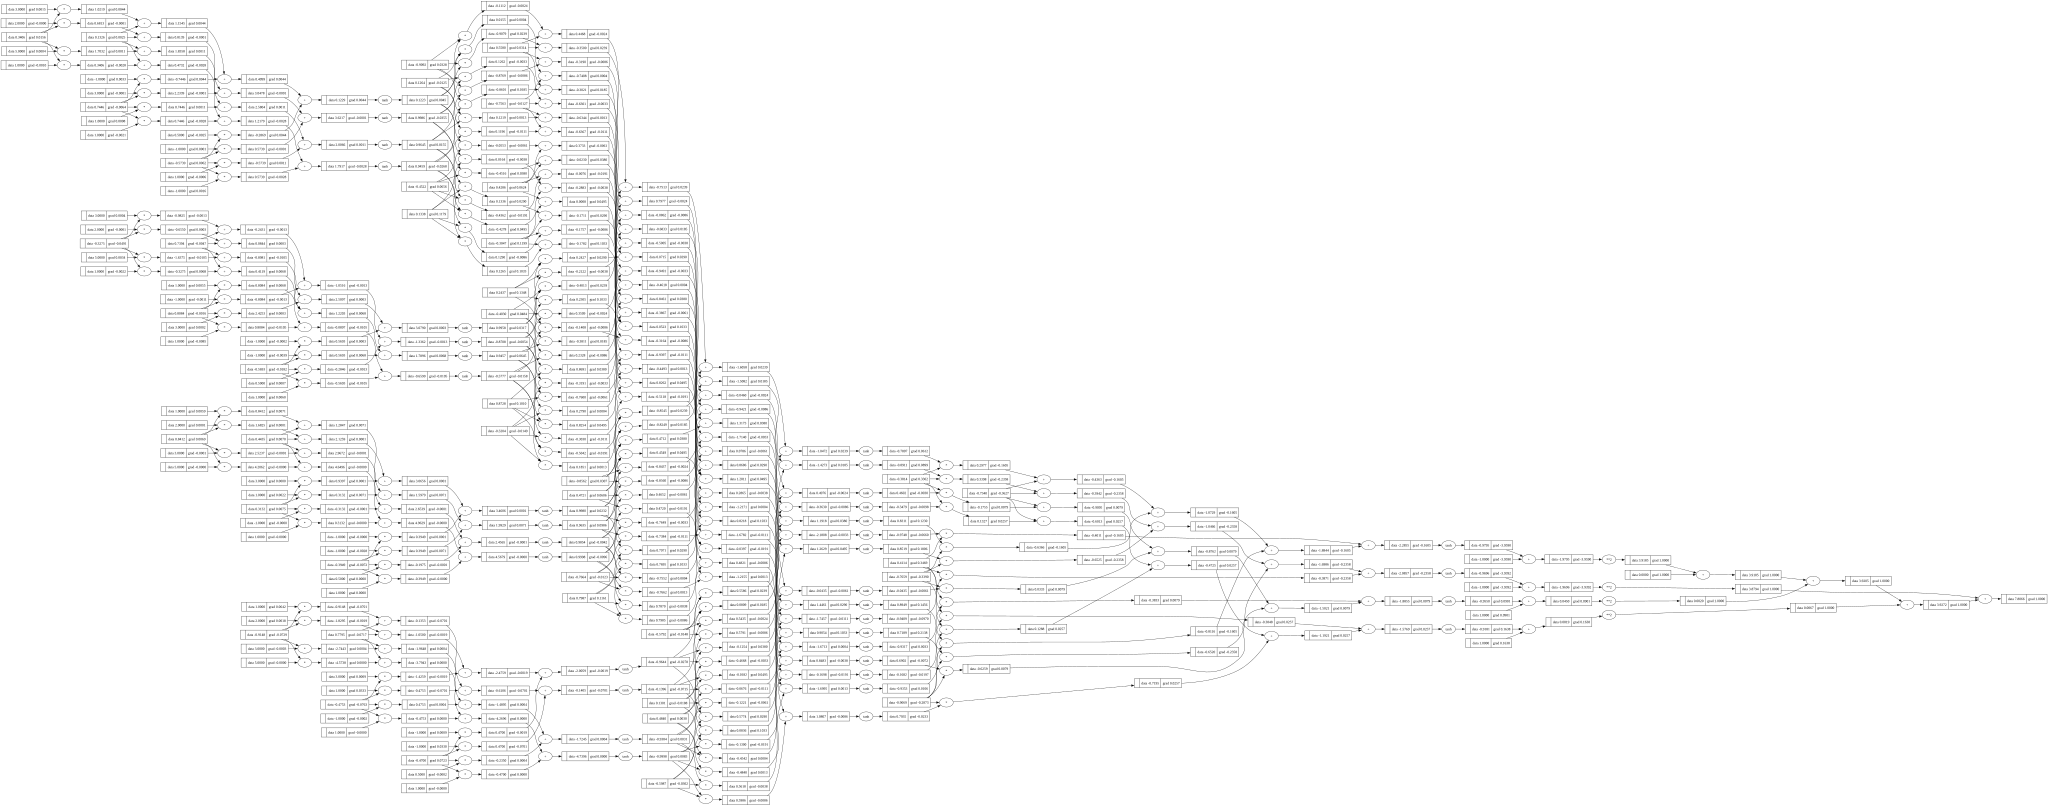

In [299]:
draw_dot(loss)

In [300]:
n.parameters()

[Value(data=0.3406456944630136),
 Value(data=0.7446421807032282),
 Value(data=-0.5738860717716041),
 Value(data=0.13257260279111538),
 Value(data=-0.3275028472610768),
 Value(data=0.8084442768899625),
 Value(data=-0.5692720606874839),
 Value(data=0.7393702393954573),
 Value(data=0.8412326046320591),
 Value(data=0.3132323129678274),
 Value(data=-0.3949392358095323),
 Value(data=0.44348421987743003),
 Value(data=-0.9147652359373708),
 Value(data=-0.47529516020606755),
 Value(data=-0.4700285879815753),
 Value(data=0.7795060841571677),
 Value(data=-0.909238492670184),
 Value(data=-0.4030219837311899),
 Value(data=-0.8561581903565574),
 Value(data=-0.5792057744765116),
 Value(data=0.5579685251040045),
 Value(data=-0.4522492575701491),
 Value(data=0.8727524534092008),
 Value(data=0.47213126761224733),
 Value(data=0.13006173075115712),
 Value(data=0.42859485942108133),
 Value(data=0.13377667981939756),
 Value(data=0.24368108255569898),
 Value(data=0.7986690298714068),
 Value(data=-0.598724645

In [301]:
n.layers[0].neurons[0].w[0].data

0.3406456944630136

In [302]:
learning_rate = 0.01

for p in n.parameters():
    p.data += -learning_rate * p.grad

In [303]:
n.layers[0].neurons[0].w[0].data

0.34049010835376237

In [304]:
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.9788175852726825),
 Value(data=-0.9542641604102965),
 Value(data=-0.9163725193486194),
 Value(data=-0.9684825710351767)]

In [305]:
loss = sum((yout - ygt) ** 2 for yout, ygt in zip(ypred, ys))
loss

Value(data=7.799727990796741)

### Gradient Descent

In [366]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt) ** 2 for yout, ygt in zip(ypred, ys))
loss

Value(data=0.1911545730633711)

In [367]:
loss.backward()

In [369]:
learning_rate = 0.01

for p in n.parameters():
    p.data += -learning_rate * p.grad

In [370]:
ypred

[Value(data=0.9970611971656496),
 Value(data=-0.6817474012406791),
 Value(data=-0.7002423858834517),
 Value(data=0.9974323817719234)]